In [1]:
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
df = pd.read_csv("austo_automobile.csv")

In [3]:
df.head()                               # first 5 rows retrive

,Age,Gender,Profession,Marital_status,Education,No_of_Dependents,Personal_loan,House_loan,Partner_working,Salary,Partner_salary,Total_salary,Price,Make
0,53,Male,Business,Married,Post Graduate,4,No,No,Yes,99300,70700.0,170000,61000,SUV
1,53,Femal,Salaried,Married,Post Graduate,4,Yes,No,Yes,95500,70300.0,165800,61000,SUV
2,53,Female,Salaried,Married,Post Graduate,3,No,No,Yes,97300,60700.0,158000,57000,SUV
3,53,Female,Salaried,Married,Graduate,2,Yes,No,Yes,72500,70300.0,142800,61000,SUV
4,53,Male,Salaried,Married,Post Graduate,3,No,No,Yes,79700,60200.0,139900,57000,SUV


In [4]:
df.shape               # rows and columns count 

(1581, 14)

In [5]:
df.columns           # only columns names   (Data profiling)

Index(['Age', 'Gender', 'Profession', 'Marital_status', 'Education',
       'No_of_Dependents', 'Personal_loan', 'House_loan', 'Partner_working',
       'Salary', 'Partner_salary', 'Total_salary', 'Price', 'Make'],
      dtype='str')

In [6]:
df.dtypes             # data type checking

Age                   int64
Gender                  str
Profession              str
Marital_status          str
Education               str
No_of_Dependents      int64
Personal_loan           str
House_loan              str
Partner_working         str
Salary                int64
Partner_salary      float64
Total_salary          int64
Price                 int64
Make                    str
dtype: object

In [7]:
df.info()                             # data information 

<class 'pandas.DataFrame'>
RangeIndex: 1581 entries, 0 to 1580
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Age               1581 non-null   int64  
 1   Gender            1528 non-null   str    
 2   Profession        1581 non-null   str    
 3   Marital_status    1581 non-null   str    
 4   Education         1581 non-null   str    
 5   No_of_Dependents  1581 non-null   int64  
 6   Personal_loan     1581 non-null   str    
 7   House_loan        1581 non-null   str    
 8   Partner_working   1581 non-null   str    
 9   Salary            1581 non-null   int64  
 10  Partner_salary    1475 non-null   float64
 11  Total_salary      1581 non-null   int64  
 12  Price             1581 non-null   int64  
 13  Make              1581 non-null   str    
dtypes: float64(1), int64(5), str(8)
memory usage: 173.1 KB


In [8]:
df.describe()         # describtion of numerical columns

,Age,No_of_Dependents,Salary,Partner_salary,Total_salary,Price
count,1581.000000,1581.000000,1581.000000,1475.000000,1581.000000,1581.000000
mean,31.922201,2.457938,60392.220114,20225.559322,79625.996205,35597.722960
std,8.425978,0.943483,14674.825044,19573.149277,25545.857768,13633.636545
min,22.000000,0.000000,30000.000000,0.000000,30000.000000,18000.000000
25%,25.000000,2.000000,51900.000000,0.000000,60500.000000,25000.000000
50%,29.000000,2.000000,59500.000000,25600.000000,78000.000000,31000.000000
75%,38.000000,3.000000,71800.000000,38300.000000,95900.000000,47000.000000
max,54.000000,4.000000,99300.000000,80500.000000,171000.000000,70000.000000


In [9]:
df.isnull().sum()                       # data Quality check       missing value checking

Age                   0
Gender               53
Profession            0
Marital_status        0
Education             0
No_of_Dependents      0
Personal_loan         0
House_loan            0
Partner_working       0
Salary                0
Partner_salary      106
Total_salary          0
Price                 0
Make                  0
dtype: int64

In [10]:
df.duplicated().sum()                 # data quality check    (duplicates value checking)

np.int64(0)

In [11]:
df.Gender.unique()

<StringArray>
['Male', 'Femal', 'Female', nan, 'Femle']
Length: 5, dtype: str

In [12]:
df.Make.unique()

<StringArray>
['SUV', 'Sedan', 'Hatchback']
Length: 3, dtype: str

In [13]:
df[[ 'Gender', 'Profession', 'Marital_status', 'Education',
       'No_of_Dependents', 'Personal_loan', 'House_loan', 'Partner_working',
        'Make']].apply(lambda x:x.unique())                                   # each column unique checking

Gender              [Male, Femal, Female, nan, Femle]
Profession                       [Business, Salaried]
Marital_status                      [Married, Single]
Education                   [Post Graduate, Graduate]
No_of_Dependents                      [4, 3, 2, 1, 0]
Personal_loan                               [No, Yes]
House_loan                                  [No, Yes]
Partner_working                             [Yes, No]
Make                          [SUV, Sedan, Hatchback]
dtype: object

In [14]:
df.Gender.value_counts(dropna=False)          # (dropna = False) = missing values irunthall athaiyum  count -il include seigirathu

Gender
Male      1199
Female     327
NaN         53
Femal        1
Femle        1
Name: count, dtype: int64

In [15]:
df.Gender = df.Gender.replace(["Femal" , "Femle"], ["Female" , "Female"])          # correct the spelling mistake

In [16]:
df["Gender"].value_counts(dropna = False)

Gender
Male      1199
Female     329
NaN         53
Name: count, dtype: int64

In [17]:
df.Gender = df.Gender.fillna("Male")

In [18]:
df["Partner_salary"] = df["Total_salary"]- df["Salary"]

In [19]:
df.isnull().sum()

Age                 0
Gender              0
Profession          0
Marital_status      0
Education           0
No_of_Dependents    0
Personal_loan       0
House_loan          0
Partner_working     0
Salary              0
Partner_salary      0
Total_salary        0
Price               0
Make                0
dtype: int64

# EDA - Exploration Data Analysis

In [20]:
# univariate Analysis - single columns based analysis

In [21]:
df.Gender.value_counts()

Gender
Male      1252
Female     329
Name: count, dtype: int64

<Axes: xlabel='Gender', ylabel='count'>

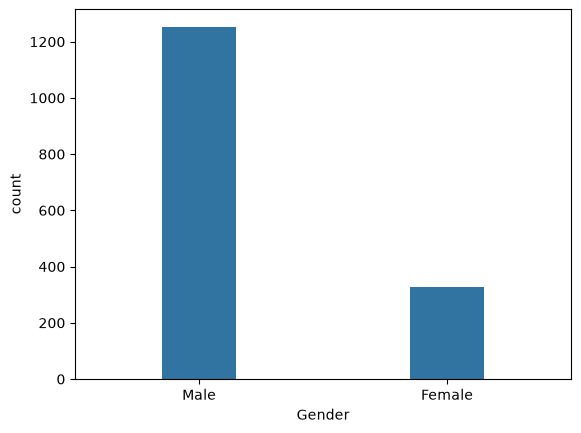

In [22]:
import seaborn as sns
sns.countplot(x = df.Gender, width=0.3)

In [23]:
df.Make.value_counts()

Make
Sedan        702
Hatchback    582
SUV          297
Name: count, dtype: int64

<Axes: xlabel='Make', ylabel='count'>

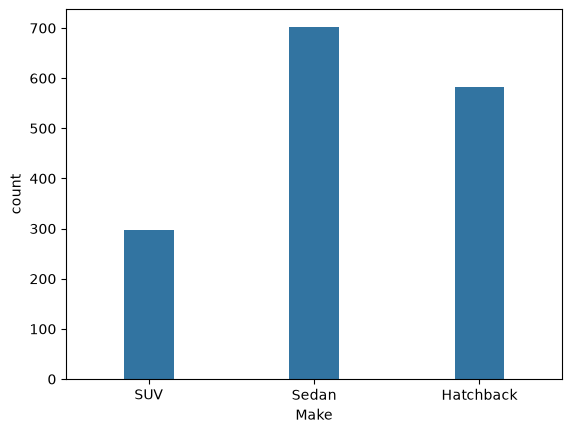

In [24]:
sns.countplot(x= df.Make, width=0.3)

<Axes: xlabel='Salary', ylabel='Count'>

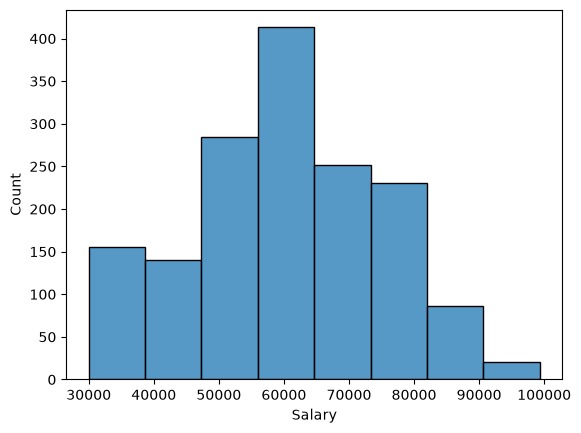

In [25]:
sns.histplot(df.Salary, bins=8)

# 2: Bi-variate Analysis - two column based analysis

In [26]:
df.groupby(["Gender", "Make"])["Make"].agg(["count","max", "min"])

count        max        min
Gender Make                                  
Female Hatchback     15  Hatchback  Hatchback
       SUV          173        SUV        SUV
       Sedan        141      Sedan      Sedan
Male   Hatchback    567  Hatchback  Hatchback
       SUV          124        SUV        SUV
       Sedan        561      Sedan      Sedan

In [27]:
df.groupby(["Gender", "Make"])["Make"].count()

Gender  Make     
Female  Hatchback     15
        SUV          173
        Sedan        141
Male    Hatchback    567
        SUV          124
        Sedan        561
Name: Make, dtype: int64

In [28]:
male = df[df.Gender=="Male"][["Gender", "Make"]]
male

,Gender,Make
0,Male,SUV
4,Male,SUV
7,Male,SUV
8,Male,SUV
9,Male,SUV
...,...,...
1576,Male,Hatchback
1577,Male,Hatchback
1578,Male,Hatchback
1579,Male,Hatchback


In [29]:
female = df[df.Gender=="Female"][["Gender", "Make"]]
female

,Gender,Make
1,Female,SUV
2,Female,SUV
3,Female,SUV
5,Female,SUV
6,Female,SUV
...,...,...
1350,Female,Hatchback
1389,Female,Hatchback
1503,Female,Hatchback
1518,Female,Hatchback


In [30]:
female.shape

(329, 2)

In [31]:
df.groupby(["Personal_loan", "Make"])["Make"].count()

Personal_loan  Make     
No             Hatchback    291
               SUV          181
               Sedan        317
Yes            Hatchback    291
               SUV          116
               Sedan        385
Name: Make, dtype: int64

In [32]:
No = df[df.Personal_loan == "No"][["Personal_loan","Make"]]
No

,Personal_loan,Make
0,No,SUV
2,No,SUV
4,No,SUV
5,No,SUV
7,No,SUV
...,...,...
1571,No,Hatchback
1576,No,Hatchback
1577,No,Hatchback
1578,No,Hatchback


In [33]:
Yes = df[df.Personal_loan == "Yes"][["Personal_loan", "Make"]]
Yes

,Personal_loan,Make
1,Yes,SUV
3,Yes,SUV
6,Yes,SUV
10,Yes,SUV
12,Yes,SUV
...,...,...
1572,Yes,Hatchback
1573,Yes,Hatchback
1574,Yes,Sedan
1575,Yes,Hatchback


In [34]:
male.shape

(1252, 2)

In [35]:
sam1 = pd.DataFrame(male.sample(329).groupby("Make")["Make"].count()).rename(columns = {"Make" : "Male"})

In [36]:
sam2 = pd.DataFrame(male.sample(329).groupby("Make")["Make"].count()).rename(columns = {"Make" : "Male"})

In [37]:
sam3 = pd.DataFrame(female.sample(329).groupby("Make")["Make"].count()).rename(columns = {"Make" : "female"})

In [38]:
fem = pd.DataFrame(female.sample(329).groupby("Make")["Make"].count()).rename(columns = {"Make" : "female"})

In [39]:
import matplotlib as plt

<Axes: xlabel='Make'>

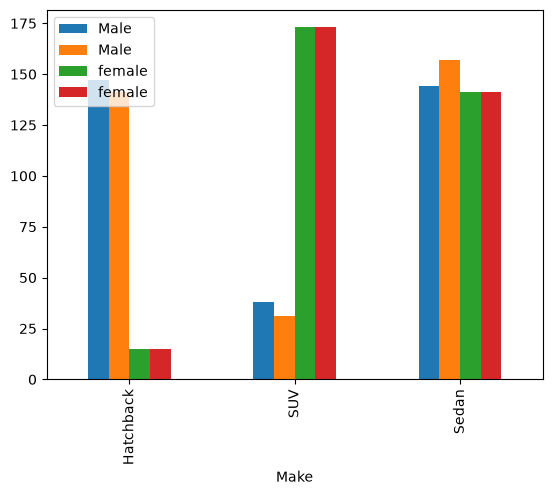

In [40]:
pd.concat([sam1,sam2,sam3,fem], axis=1).plot.bar()

In [41]:
#profession  vs Make

In [42]:
Profession = df[["Profession", "Make"]]
Profession.Profession.value_counts()

Profession
Salaried    896
Business    685
Name: count, dtype: int64

In [43]:
sal = df[df.Profession=="Salaried"][["Profession","Make"]]
sal

,Profession,Make
1,Salaried,SUV
2,Salaried,SUV
3,Salaried,SUV
4,Salaried,SUV
5,Salaried,SUV
...,...,...
1569,Salaried,Hatchback
1574,Salaried,Sedan
1575,Salaried,Hatchback
1576,Salaried,Hatchback


In [44]:
bus =  df[df.Profession=="Business"][["Profession","Make"]]
bus

,Profession,Make
0,Business,SUV
14,Business,SUV
16,Business,SUV
18,Business,SUV
22,Business,SUV
...,...,...
1572,Business,Hatchback
1573,Business,Hatchback
1577,Business,Hatchback
1578,Business,Hatchback


In [45]:
Salary = pd.DataFrame(sal.sample(685).groupby("Make")["Make"].count()).rename(columns ={"Make":"Salaried"})
Salary

,Salaried
Make,
Hatchback,224
SUV,157
Sedan,304


In [46]:
business = pd.DataFrame(bus.groupby("Make")["Make"].count()).rename(columns = {"Make":"business"})

In [47]:
business

,business
Make,
Hatchback,290
SUV,89
Sedan,306


<Axes: xlabel='Make'>

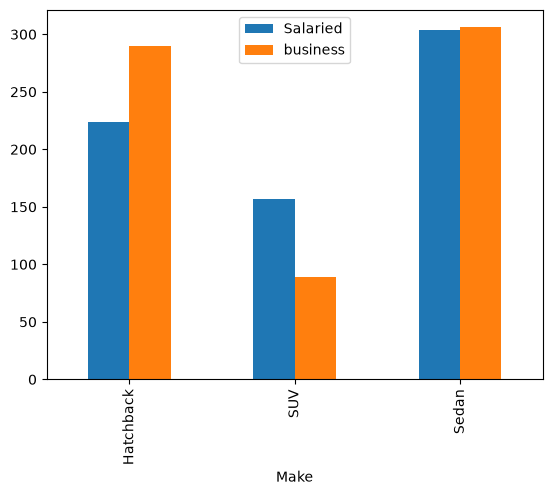

In [48]:
pd.concat([Salary,business],axis=1).plot.bar()

# Multi-variate Analysis---
Gender, marital_status, make

In [49]:
new = df.groupby(["Gender", "Marital_status", "Make"])["Make"].count()
new

Gender  Marital_status  Make     
Female  Married         Hatchback     14
                        SUV          166
                        Sedan        127
        Single          Hatchback      1
                        SUV            7
                        Sedan         14
Male    Married         Hatchback    484
                        SUV          115
                        Sedan        537
        Single          Hatchback     83
                        SUV            9
                        Sedan         24
Name: Make, dtype: int64

<Axes: xlabel='Gender,Marital_status,Make'>

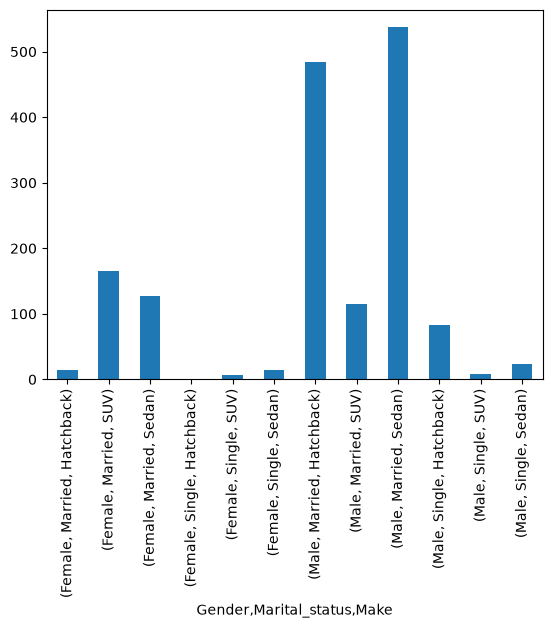

In [50]:
new.plot.bar()

In [51]:
pd.crosstab(df.Gender, df.Make)

Make,Hatchback,SUV,Sedan
Gender,,,
Female,15,173,141
Male,567,124,561


In [52]:
pd.pivot_table(df,index="Gender",values = "Price", columns="Make", aggfunc="sum")

Make,Hatchback,SUV,Sedan
Gender,,,
Female,412000,9252000,6031000
Male,14996000,7328000,18261000


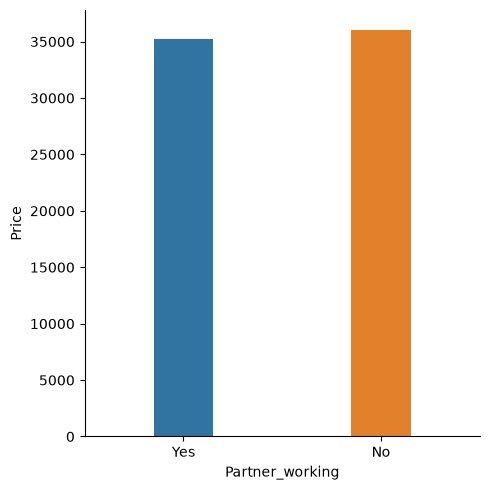

In [53]:
sns.catplot(df, x="Partner_working", y="Price", kind="bar", width=0.3, errorbar=None, hue="Partner_working")
# there is no significance difference with working partner---

In [54]:
df.columns

Index(['Age', 'Gender', 'Profession', 'Marital_status', 'Education',
       'No_of_Dependents', 'Personal_loan', 'House_loan', 'Partner_working',
       'Salary', 'Partner_salary', 'Total_salary', 'Price', 'Make'],
      dtype='str')

In [55]:
new = df.groupby(["Gender", "Marital_status", "Make"])["Make"].count()

<Axes: xlabel='Gender,Marital_status'>

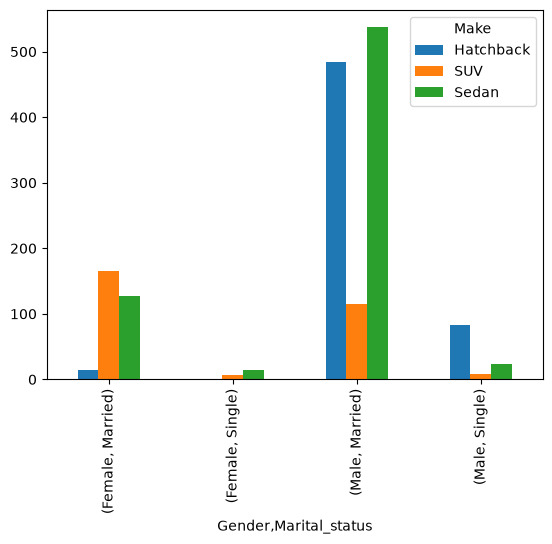

In [56]:
new.unstack().plot.bar()

In [57]:
df.columns


Index(['Age', 'Gender', 'Profession', 'Marital_status', 'Education',
       'No_of_Dependents', 'Personal_loan', 'House_loan', 'Partner_working',
       'Salary', 'Partner_salary', 'Total_salary', 'Price', 'Make'],
      dtype='str')

<Axes: xlabel='Gender', ylabel='Personal_loan'>

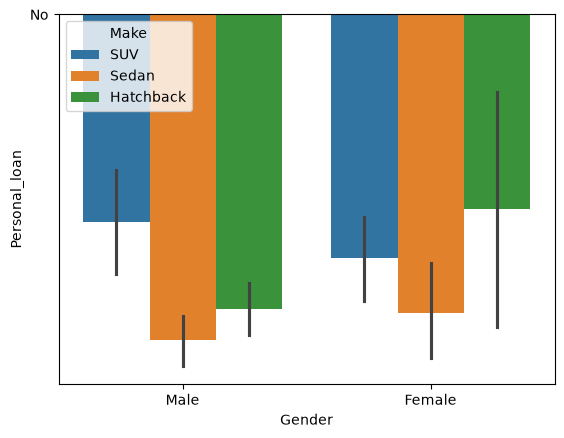

In [66]:
sns.barplot(df, x = "Gender", y = "Personal_loan", hue="Make")